## Question 1 – Data Acquisition
Load the CSV using Pandas and inspect the first five rows, shape and data types. The original data is kept unchanged for the quality report.

In [7]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from IPython.display import display

# Load dataset
original = pd.read_csv('student_performance.csv')


print("\033[1;36m" + "=" * 45)
print("       STUDENT PERFORMANCE DATASET")
print("=" * 45 + "\033[0m")


display(original.head().style.background_gradient(cmap='YlGnBu'))


print("\033[1;32mDataset shape:\033[0m", original.shape)


print("\033[1;35m\nDataset Information:\033[0m")
original.info()


       STUDENT PERFORMANCE DATASET


,Student_ID,Name,Age,Gender,Study_Hours,Attendance,Exam_Marks
0,DS001,Nimal Perera,21.000000,Male,12.000000,85.000000,78.000000
1,DS002,Kavindi Silva,22.000000,female,8.000000,92.000000,88.000000
2,DS003,Sahan Fernando,20.000000,M,5.000000,68.000000,45.000000
3,DS004,Tharushi Jayasinghe,21.000000,Female,nan,78.000000,63.000000
4,DS005,Dilan Peris,23.000000,male,15.000000,88.000000,91.000000


Dataset shape: (12, 7)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Student_ID   12 non-null     object 
 1   Name         12 non-null     object 
 2   Age          11 non-null     float64
 3   Gender       12 non-null     object 
 4   Study_Hours  11 non-null     float64
 5   Attendance   11 non-null     float64
 6   Exam_Marks   11 non-null     float64
dtypes: float64(4), object(3)
memory usage: 804.0+ bytes


## Question 2 – Data Cleaning
Identify missing values and exact duplicate rows. Remove duplicates **before** computing replacement statistics so repeated students do not affect them. Standardize names by trimming whitespace, collapsing extra spaces and using title case. Map gender abbreviations and different letter cases to Male/Female. Replace missing numerical values with the median of each column, which is less sensitive to extreme values than the mean. Imputed examination marks are estimates, so retain a flag for interpretation.

In [8]:
missing_original = original.isna().sum()
duplicates_original = int(original.duplicated().sum())

print("\033[1;36m" + "=" * 45)
print("       DATA QUALITY CHECK")
print("=" * 45 + "\033[0m")

print("\033[1;33m\nMissing values by column:\033[0m")
display(missing_original.to_frame('Missing values').style.background_gradient(cmap='YlOrRd'))

print("\033[1;32mTotal missing values:\033[0m", int(missing_original.sum()))
print("\033[1;35mExact duplicate records:\033[0m", duplicates_original)

print("\033[1;34m\nDuplicate Records:\033[0m")
display(original.loc[original.duplicated(keep=False)].style.background_gradient(cmap='PuBu'))

       DATA QUALITY CHECK

Missing values by column:


,Missing values
Student_ID,0
Name,0
Age,1
Gender,0
Study_Hours,1
Attendance,1
Exam_Marks,1


Total missing values: 4
Exact duplicate records: 1

Duplicate Records:


,Student_ID,Name,Age,Gender,Study_Hours,Attendance,Exam_Marks
4,DS005,Dilan Peris,23.000000,male,15.000000,88.000000,91.000000
10,DS005,Dilan Peris,23.000000,male,15.000000,88.000000,91.000000


In [9]:

cleaned = original.drop_duplicates().copy()

cleaned['Name'] = cleaned['Name'].str.strip().str.replace(r'\s+', ' ', regex=True).str.title()

gender_map = {'m': 'Male', 'male': 'Male', 'f': 'Female', 'female': 'Female'}
cleaned['Gender'] = cleaned['Gender'].str.strip().str.lower().map(gender_map)

cleaned['Exam_Marks_Imputed'] = cleaned['Exam_Marks'].isna()

numeric_columns = ['Age', 'Study_Hours', 'Attendance', 'Exam_Marks']
replacement_values = cleaned[numeric_columns].median()

print("\033[1;36m" + "=" * 50)
print("       MEDIAN REPLACEMENT VALUES")
print("=" * 50 + "\033[0m")
display(replacement_values.to_frame('Median').style.background_gradient(cmap='YlGnBu'))

cleaned[numeric_columns] = cleaned[numeric_columns].fillna(replacement_values)
cleaned = cleaned.reset_index(drop=True)

print("\033[1;32m\nCLEANED DATASET\033[0m")
display(cleaned.style.background_gradient(cmap='PuBu'))

print("\033[1;33mRemaining missing values:\033[0m", int(cleaned.isna().sum().sum()))
print("\033[1;35mRemaining duplicate records:\033[0m", int(cleaned.duplicated().sum()))


       MEDIAN REPLACEMENT VALUES


,Median
Age,21.000000
Study_Hours,8.500000
Attendance,82.000000
Exam_Marks,69.000000



CLEANED DATASET


,Student_ID,Name,Age,Gender,Study_Hours,Attendance,Exam_Marks,Exam_Marks_Imputed
0,DS001,Nimal Perera,21.000000,Male,12.000000,85.000000,78.000000,False
1,DS002,Kavindi Silva,22.000000,Female,8.000000,92.000000,88.000000,False
2,DS003,Sahan Fernando,20.000000,Male,5.000000,68.000000,45.000000,False
3,DS004,Tharushi Jayasinghe,21.000000,Female,8.500000,78.000000,63.000000,False
4,DS005,Dilan Peris,23.000000,Male,15.000000,88.000000,91.000000,False
5,DS006,Ishara Kumari,21.000000,Female,7.000000,82.000000,52.000000,False
6,DS007,Ravindu Bandara,22.000000,Male,10.000000,74.000000,71.000000,False
7,DS008,Madhavi Fernando,21.000000,Female,4.000000,81.000000,39.000000,False
8,DS009,Kasun Madushanka,20.000000,Male,9.000000,95.000000,76.000000,False
9,DS010,Dinithi Rajapaksha,22.000000,Female,6.000000,72.000000,69.000000,True


Remaining missing values: 0
Remaining duplicate records: 0


## Question 3 – Data Transformation
Min-Max normalization uses `(x − minimum) / (maximum − minimum)` to scale study hours into [0, 1]. Preserve the original study hours and gender alongside the transformed columns. Label encoding assigns Female = 0 and Male = 1; these codes do not indicate an order. Examination marks of 50 or above are classified as Pass.

In [10]:

minimum = cleaned['Study_Hours'].min()
maximum = cleaned['Study_Hours'].max()

cleaned['Study_Hours_Normalized'] = (cleaned['Study_Hours'] - minimum) / (maximum - minimum)

encoder = LabelEncoder()
cleaned['Gender_Encoded'] = encoder.fit_transform(cleaned['Gender'])

print("\033[1;36m" + "=" * 45)
print("       GENDER LABEL ENCODING")
print("=" * 45 + "\033[0m")

print("\033[1;33mGender encoding:\033[0m", dict(zip(encoder.classes_, encoder.transform(encoder.classes_))))

cleaned['Performance'] = np.where(cleaned['Exam_Marks'] >= 50, 'Pass', 'Fail')

print("\033[1;32m\nSTUDENT PERFORMANCE DETAILS\033[0m")

display(cleaned[['Student_ID', 'Name', 'Study_Hours', 'Study_Hours_Normalized',
                 'Gender', 'Gender_Encoded', 'Exam_Marks', 'Exam_Marks_Imputed', 'Performance']]
        .style.background_gradient(cmap='YlGnBu'))

print("\033[1;35m\nPERFORMANCE COUNTS\033[0m")

display(cleaned['Performance'].value_counts().to_frame('Students')
        .style.background_gradient(cmap='RdYlGn'))


       GENDER LABEL ENCODING
Gender encoding: {'Female': np.int64(0), 'Male': np.int64(1)}

STUDENT PERFORMANCE DETAILS


,Student_ID,Name,Study_Hours,Study_Hours_Normalized,Gender,Gender_Encoded,Exam_Marks,Exam_Marks_Imputed,Performance
0,DS001,Nimal Perera,12.000000,0.727273,Male,1,78.000000,False,Pass
1,DS002,Kavindi Silva,8.000000,0.363636,Female,0,88.000000,False,Pass
2,DS003,Sahan Fernando,5.000000,0.090909,Male,1,45.000000,False,Fail
3,DS004,Tharushi Jayasinghe,8.500000,0.409091,Female,0,63.000000,False,Pass
4,DS005,Dilan Peris,15.000000,1.000000,Male,1,91.000000,False,Pass
5,DS006,Ishara Kumari,7.000000,0.272727,Female,0,52.000000,False,Pass
6,DS007,Ravindu Bandara,10.000000,0.545455,Male,1,71.000000,False,Pass
7,DS008,Madhavi Fernando,4.000000,0.000000,Female,0,39.000000,False,Fail
8,DS009,Kasun Madushanka,9.000000,0.454545,Male,1,76.000000,False,Pass
9,DS010,Dinithi Rajapaksha,6.000000,0.181818,Female,0,69.000000,True,Pass



PERFORMANCE COUNTS


,Students
Performance,
Pass,9
Fail,2


## Question 4 – Data Filtering and Quality Analysis
Attendance must be strictly greater than 75%; examination marks must be at least 75. These filters use cleaned values, including median replacements. The imputation flag identifies any estimated examination score.

In [11]:

high_attendance = cleaned.loc[cleaned['Attendance'] > 75]

print("\033[1;36m" + "=" * 45)
print("       HIGH ATTENDANCE STUDENTS")
print("=" * 45 + "\033[0m")

print("\033[1;32mStudents with attendance above 75%:\033[0m", len(high_attendance))

display(high_attendance[['Student_ID', 'Name', 'Attendance']]
        .style.background_gradient(cmap='YlGnBu'))

high_marks = cleaned.loc[cleaned['Exam_Marks'] >= 75]

print("\033[1;35m\nHIGH EXAM MARKS STUDENTS\033[0m")

print("\033[1;32mStudents scoring 75 or above:\033[0m", len(high_marks))

display(high_marks[['Student_ID', 'Name', 'Exam_Marks', 'Exam_Marks_Imputed']]
        .style.background_gradient(cmap='YlOrRd'))

print("\033[1;34m\nORIGINAL DATASET QUALITY REPORT\033[0m")

display(missing_original.to_frame('Missing values')
        .style.background_gradient(cmap='OrRd'))

print("\033[1;33mOriginal total missing values:\033[0m", int(missing_original.sum()))
print("\033[1;31mOriginal duplicate records:\033[0m", duplicates_original)


       HIGH ATTENDANCE STUDENTS
Students with attendance above 75%: 8


,Student_ID,Name,Attendance
0,DS001,Nimal Perera,85.000000
1,DS002,Kavindi Silva,92.000000
3,DS004,Tharushi Jayasinghe,78.000000
4,DS005,Dilan Peris,88.000000
5,DS006,Ishara Kumari,82.000000
7,DS008,Madhavi Fernando,81.000000
8,DS009,Kasun Madushanka,95.000000
10,DS011,Shehan Wijesinghe,83.000000



HIGH EXAM MARKS STUDENTS
Students scoring 75 or above: 4


,Student_ID,Name,Exam_Marks,Exam_Marks_Imputed
0,DS001,Nimal Perera,78.000000,False
1,DS002,Kavindi Silva,88.000000,False
4,DS005,Dilan Peris,91.000000,False
8,DS009,Kasun Madushanka,76.000000,False



ORIGINAL DATASET QUALITY REPORT


,Missing values
Student_ID,0
Name,0
Age,1
Gender,0
Study_Hours,1
Attendance,1
Exam_Marks,1


Original total missing values: 4
Original duplicate records: 1


## Question 5 – Visualization
The chart shows each student’s cleaned examination mark. The orange bar marks a median-imputed score, and the dashed line shows the pass threshold.

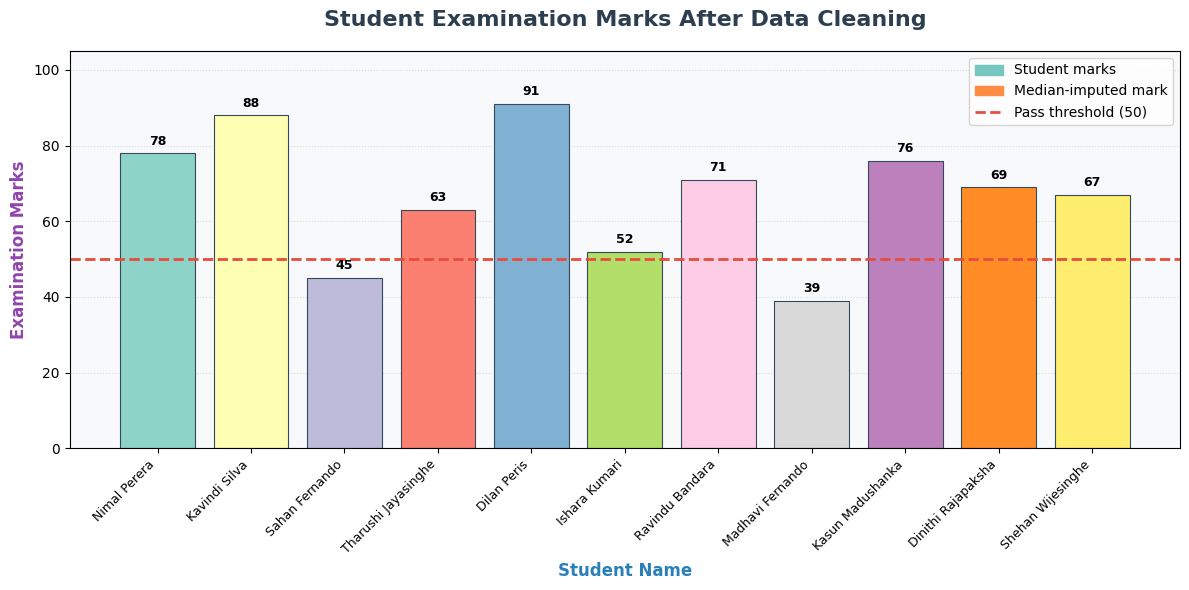

In [13]:

fig, ax = plt.subplots(figsize=(12, 6))

# Different colours for student marks
colors = plt.cm.Set3(np.linspace(0, 1, len(cleaned)))

# Highlight median-imputed marks in orange
colors = np.where(
    cleaned['Exam_Marks_Imputed'].to_numpy()[:, None],
    np.array([1.0, 0.55, 0.15, 1.0]),
    colors
)

bars = ax.bar(
    cleaned['Name'],
    cleaned['Exam_Marks'],
    color=colors,
    edgecolor='#34495e',
    linewidth=0.8
)

ax.bar_label(bars, fmt='%.0f', padding=4, fontsize=9, fontweight='bold')

# Pass threshold
ax.axhline(
    50, color='#e74c3c', linestyle='--',
    linewidth=2, label='Pass threshold (50)'
)

from matplotlib.patches import Patch

ax.legend(handles=[
    Patch(color='#76c7c0', label='Student marks'),
    Patch(color='#ff8c42', label='Median-imputed mark'),
    plt.Line2D([0], [0], color='#e74c3c', linestyle='--',
               linewidth=2, label='Pass threshold (50)')
], loc='upper right', frameon=True)

# Chart title and labels
ax.set_title(
    'Student Examination Marks After Data Cleaning',
    fontsize=16, fontweight='bold', color='#2c3e50', pad=18
)
ax.set_xlabel('Student Name', fontsize=12, fontweight='bold', color='#2980b9')
ax.set_ylabel('Examination Marks', fontsize=12, fontweight='bold', color='#8e44ad')

ax.set_ylim(0, 105)
ax.tick_params(axis='x', rotation=45, labelsize=9)
plt.setp(ax.get_xticklabels(), ha='right')

ax.set_facecolor('#f8f9fa')
fig.patch.set_facecolor('#ffffff')
ax.grid(axis='y', linestyle=':', alpha=0.4)
ax.set_axisbelow(True)

fig.tight_layout()
fig.savefig('examination_marks.png', dpi=160, bbox_inches='tight')
plt.show()


## Conclusion
The original dataset contained 12 records, four missing values and one duplicate record. Removing the duplicate left 11 unique students. Missing age, study hours, attendance and examination marks were replaced with their column medians (21, 8.5, 82 and 69 respectively). Names and gender values were standardized to improve consistency. Study hours were normalized, gender was encoded and examination marks were classified into Pass or Fail. Nine students passed and two failed; eight students had attendance above 75%, and four scored at least 75. Dinithi’s examination mark of 69 is an imputed estimate, so her Pass classification should be confirmed using the actual result. Cleaning improves completeness and consistency but does not independently verify the accuracy of the original values.

In [14]:
cleaned.to_csv('student_performance_cleaned.csv', index=False)
print('Saved student_performance_cleaned.csv')

Saved student_performance_cleaned.csv
